In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

warnings.filterwarnings("ignore")
sc.settings.set_figure_params(dpi=150, facecolor="white")

c:\Users\taylorhearn\AppData\Local\miniforge3\envs\sequencing\lib\site-packages\louvain\__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
def save_figure(fig, output_dir=None, filename=None):
    """Save a matplotlib figure when output args are provided."""
    if output_dir is None or filename is None:
        return
    output_path = Path(output_dir) / filename
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, bbox_inches="tight")

In [3]:
def get_present_and_missing_genes(adata, genes, use_raw=True):
    """Split provided genes into present and missing lists."""
    valid_genes = set(adata.raw.var_names) if use_raw and adata.raw is not None else set(adata.var_names)
    present = [gene for gene in genes if gene in valid_genes]
    missing = [gene for gene in genes if gene not in valid_genes]
    return present, missing

In [4]:
def ensure_obs_categories_and_palettes(adata, cluster_colormap, condition_colormap):
    """Normalize categorical fields and align Scanpy color arrays."""
    adata.obs["clusters"] = adata.obs["clusters"].astype("category")
    adata.obs["condition"] = adata.obs["condition"].astype("category")
    adata.obs["sample"] = adata.obs["sample"].astype("category")

    adata.uns["clusters_colors"] = [cluster_colormap[c] for c in adata.obs["clusters"].cat.categories]
    adata.uns["condition_colors"] = [condition_colormap[c] for c in adata.obs["condition"].cat.categories]
    adata.uns["sample_colors"] = [
        plt.matplotlib.colors.to_hex(c)
        for c in plt.get_cmap("tab20").colors[: adata.obs["sample"].cat.categories.size]
    ]

In [5]:
def highlight_umap(adata, groupby, size=10, ncols=4, na_color="lightgrey", output_path=None,
    palette=None, title_prefix=""):
    """Highlight one category at a time on UMAP while greying other groups."""
    if groupby not in adata.obs.columns:
        raise ValueError(f"Column '{groupby}' was not found in adata.obs")

    groups = list(adata.obs[groupby].cat.categories) if hasattr(adata.obs[groupby], "cat") else sorted(adata.obs[groupby].unique())

    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(4 * ncols, 4 * nrows),
        gridspec_kw={"wspace": 0.3, "hspace": 0.3},
    )
    axes = np.atleast_1d(axes).ravel()

    for ax, group in zip(axes, groups):
        panel_palette = [palette[group]] if palette and group in palette else None
        sc.pl.umap(adata, color=groupby, groups=[group], na_color=na_color,
            size=size, title=f"{title_prefix}{group}",
            legend_loc=None, frameon=False, show=False, ax=ax, palette=panel_palette)

    for ax in axes[len(groups):]:
        ax.axis("off")

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, bbox_inches="tight")

    plt.show()

In [6]:
def understand_marker_genes(adata, sig_1_list, sig_2_list, output_dir=None, thresh=0.0,
    filename="sig1_sig2_markers.png", sig1_name="sig1", sig2_name="sig2", use_raw=True):
    """Visualize marker signatures and classify cells as double-neg/pos or single-pos."""
    category_colours = {
        "Double-Neg": "lightgrey",
        f"{sig1_name} only": "#2E9BD3",
        f"{sig2_name} only": "#F06B2D",
        "Double-Pos": "#C32A71",
    }

    sig_1_positive, sig_1_missing = get_present_and_missing_genes(adata, sig_1_list, use_raw=use_raw)
    sig_2_positive, sig_2_missing = get_present_and_missing_genes(adata, sig_2_list, use_raw=use_raw)

    print(f"{sig1_name} genes found: {sig_1_positive}")
    print(f"{sig2_name} genes found: {sig_2_positive}")
    if sig_1_missing:
        print(f"{sig1_name} genes missing: {sig_1_missing}")
    if sig_2_missing:
        print(f"{sig2_name} genes missing: {sig_2_missing}")

    if not sig_1_positive or not sig_2_positive:
        raise ValueError(
            "At least one signature has no genes present in the dataset. "
            "Check gene symbols or annotation naming."
        )

    expr = sc.get.obs_df(adata, keys=sig_1_positive + sig_2_positive, use_raw=use_raw)
    adata.obs["sig_1_expr"] = expr[sig_1_positive].sum(axis=1)
    adata.obs["sig_2_expr"] = expr[sig_2_positive].sum(axis=1)

    x = adata.obs["sig_1_expr"].values
    y = adata.obs["sig_2_expr"].values

    double_pos = (x > thresh) & (y > thresh)
    sig1_only = (x > thresh) & (y <= thresh)
    sig2_only = (x <= thresh) & (y > thresh)
    neg = (x <= thresh) & (y <= thresh)

    rng = np.random.default_rng(0)
    jx = x + rng.uniform(-0.05, 0.05, size=x.shape)
    jy = y + rng.uniform(-0.05, 0.05, size=y.shape)

    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(9, 6))
    ax[0, 0].scatter(jx[neg], jy[neg], s=4, c=category_colours["Double-Neg"], label=f"Double-Neg ({neg.sum()})")
    ax[0, 0].scatter(jx[sig1_only], jy[sig1_only], s=4, c=category_colours[f"{sig1_name} only"], label=f"{sig1_name} only ({sig1_only.sum()})")
    ax[0, 0].scatter(jx[sig2_only], jy[sig2_only], s=4, c=category_colours[f"{sig2_name} only"], label=f"{sig2_name} only ({sig2_only.sum()})")
    ax[0, 0].scatter(jx[double_pos], jy[double_pos], s=4, c=category_colours["Double-Pos"], label=f"Double-Pos ({double_pos.sum()})")
    ax[0, 0].set_xlabel(f"{sig1_name} expression {' + '.join(sig_1_positive)}", fontsize=10)
    ax[0, 0].set_ylabel(f"{sig2_name} expression {' + '.join(sig_2_positive)}", fontsize=10)
    ax[0, 0].set_title(f"{sig1_name} vs {sig2_name} markers")
    ax[0, 0].legend(fontsize=8, loc="upper right")

    category_values = np.full(adata.n_obs, "Double-Neg", dtype=object)
    category_values[sig1_only] = f"{sig1_name} only"
    category_values[sig2_only] = f"{sig2_name} only"
    category_values[double_pos] = "Double-Pos"
    adata.obs["sig1_sig2"] = pd.Categorical(
        category_values,
        categories=["Double-Neg", f"{sig1_name} only", f"{sig2_name} only", "Double-Pos"],
    )
    adata.uns["sig1_sig2_colors"] = [category_colours[c] for c in adata.obs["sig1_sig2"].cat.categories]

    sc.pl.umap(adata, color="sig1_sig2", size=20, frameon=False, title=f"{sig1_name} vs {sig2_name} markers",
        show=False, ax=ax[0, 1])
    sc.pl.umap(adata, color="sig_1_expr", cmap="Reds", use_raw=use_raw, title=f"{sig1_name} Expression",
        frameon=False, show=False, ax=ax[1, 0])
    sc.pl.umap(adata, color="sig_2_expr", cmap="Blues", use_raw=use_raw, title=f"{sig2_name} Expression",
        frameon=False, show=False, ax=ax[1, 1])

    plt.tight_layout()
    save_figure(fig, output_dir, filename)
    plt.show()

    return {
        "sig1_genes_found": sig_1_positive,
        "sig2_genes_found": sig_2_positive,
        "sig1_genes_missing": sig_1_missing,
        "sig2_genes_missing": sig_2_missing,
    }

In [7]:
def plot_key_genes(adata, genes, output_dir=None, split_conditions=False,
    save_name="gene_umap.png", cmap="Reds", point_size=9, use_raw=True, all_present = False):
    """Plot gene expression on UMAP globally or split by condition.

    When all_present=True, plot a single overlay of only the cells that express
    every gene, coloured by the summed counts across the combined genes.
    """
    present_genes, missing_genes = get_present_and_missing_genes(adata, genes, use_raw=use_raw)
    if missing_genes:
        print(f"Skipping missing genes: {missing_genes}")

    if all_present:
        if missing_genes:
            raise ValueError(f"All genes must be present, but the following are missing: {missing_genes}")

        expr = sc.get.obs_df(adata, keys=present_genes, use_raw=use_raw)
        all_expressed = (expr > 0).all(axis=1)
        combined_expr = expr.sum(axis=1)

        combined_label = f"Combined counts: {' + '.join(present_genes)}"
        adata.obs["combined_gene_expr"] = combined_expr.to_numpy()
        subset = adata[all_expressed.to_numpy()].copy()

        print(f"Cells expressing all {len(present_genes)} genes: {subset.n_obs} / {adata.n_obs}")
        if subset.n_obs == 0:
            print("No cells express all of the provided genes; nothing to plot.")
            return {"genes_plotted": present_genes, "genes_missing": missing_genes, "n_cells": 0}

        if split_conditions:
            if "condition" not in adata.obs.columns:
                raise ValueError("'condition' column is required when split_conditions=True")

            conditions = list(adata.obs["condition"].cat.categories) if hasattr(adata.obs["condition"], "cat") else sorted(adata.obs["condition"].unique())
            vmin, vmax = 0.0, float(subset.obs["combined_gene_expr"].max())

            fig, axes = plt.subplots(ncols=len(conditions), figsize=(4 * len(conditions), 4))
            axes = np.atleast_1d(axes).ravel()
            for ax, condition in zip(axes, conditions):
                sc.pl.umap(subset[subset.obs["condition"] == condition],
                    color="combined_gene_expr", cmap=cmap,
                    vmin=vmin, vmax=vmax, colorbar_loc=None,
                    size=point_size, title=str(condition), frameon=False, show=False, ax=ax)

            sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
            fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=combined_label)
            fig.suptitle(combined_label, y=1.02, x=0.55)
            save_figure(fig, output_dir, f"combined_genes_by_condition_{save_name}")
            plt.show()
        else:
            fig, ax = plt.subplots(figsize=(5, 4))
            sc.pl.umap(subset, color="combined_gene_expr", cmap=cmap, title=combined_label,
                frameon=False, size=point_size, show=False, ax=ax)
            save_figure(fig, output_dir, f"combined_genes_{save_name}")
            plt.show()

        return {"genes_plotted": present_genes, "genes_missing": missing_genes, "n_cells": int(subset.n_obs)}

    for gene in present_genes:
        expr = sc.get.obs_df(adata, keys=[gene], use_raw=use_raw)[gene]

        if split_conditions:
            if "condition" not in adata.obs.columns:
                raise ValueError("'condition' column is required when split_conditions=True")

            conditions = list(adata.obs["condition"].cat.categories) if hasattr(adata.obs["condition"], "cat") else sorted(adata.obs["condition"].unique())
            vmin, vmax = 0.0, float(expr.max())

            fig, axes = plt.subplots(ncols=len(conditions), figsize=(4 * len(conditions), 4))
            axes = np.atleast_1d(axes).ravel()
            for ax, condition in zip(axes, conditions):
                sc.pl.umap(adata[adata.obs["condition"] == condition],
                    color=gene, cmap=cmap, use_raw=use_raw,
                    vmin=vmin, vmax=vmax, colorbar_loc=None,
                    size=point_size, title=str(condition), frameon=False, show=False, ax=ax)

            sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
            fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
            fig.suptitle(gene, y=1.02, x=0.55)
            save_figure(fig, output_dir, f"{gene}_by_condition_{save_name}")
            plt.show()
        else:
            fig, ax = plt.subplots(figsize=(5, 4))
            sc.pl.umap(adata, color=gene, cmap=cmap, use_raw=use_raw, title=str(gene),
                frameon=False, size=point_size, show=False, ax=ax )
            save_figure(fig, output_dir, f"{gene}_{save_name}")
            plt.show()

    return {"genes_plotted": present_genes, "genes_missing": missing_genes}

In [8]:
def violinplot_gene(adata, gene, groupby="clusters", output_dir=None, filename=None,
    use_raw=True,    stripplot=False,    rotation=45):
    """User-friendly wrapper for a single-gene violin plot."""
    present, _ = get_present_and_missing_genes(adata, [gene], use_raw=use_raw)
    if not present:
        raise ValueError(f"Gene '{gene}' is not available in this AnnData object")

    sc.pl.violin(adata, keys=gene, groupby=groupby, use_raw=use_raw, stripplot=stripplot,
        rotation=rotation, show=False)
    fig = plt.gcf()
    save_figure(fig, output_dir, filename)
    plt.show()

In [9]:
def dotplot_genes(adata, genes, groupby="clusters", output_dir=None, filename=None, use_raw=True):
    """User-friendly wrapper for multi-gene dotplots."""
    present_genes, missing_genes = get_present_and_missing_genes(adata, genes, use_raw=use_raw)
    if missing_genes:
        print(f"Skipping missing genes: {missing_genes}")
    if not present_genes:
        raise ValueError("None of the provided genes are available in this AnnData object")

    sc.pl.dotplot(adata, var_names=present_genes, groupby=groupby, use_raw=use_raw, show=False)
    fig = plt.gcf()
    save_figure(fig, output_dir, filename)
    plt.show()

In [10]:
def run_subcluster_pipeline(cluster_adata, output_dir, leiden_resolutions):
    """Run local subclustering and export top markers per subcluster."""
    sc.pp.highly_variable_genes(cluster_adata, n_top_genes=2000)
    sc.pp.pca(cluster_adata, n_comps=30, mask_var="highly_variable")
    sc.pp.neighbors(cluster_adata, use_rep="X_pca")
    sc.tl.umap(cluster_adata)

    cluster_adata.obs["condition"] = cluster_adata.obs["condition"].cat.remove_unused_categories()
    cluster_adata.uns.pop("condition_colors", None)

    for resolution in leiden_resolutions:
        key = f"sub_{resolution}"
        sc.tl.leiden(cluster_adata, resolution=resolution, key_added=key)
        print(cluster_adata.obs[key].value_counts())

        sc.pl.umap(cluster_adata, color=[key, "condition"], wspace=0.4, save=f"cluster2_sub_{resolution}_umap.png",
            show=True)

        sc.tl.rank_genes_groups(cluster_adata, groupby=key, method="wilcoxon", use_raw=True, rankby_abs=True)
        sc.pl.rank_genes_groups_dotplot(cluster_adata, n_genes=10, values_to_plot="scores",
            cmap="bwr", vmin=-4, vmax=4, save=f"cluster2_sub_{resolution}_dotplot.png", show=True)

        top15 = pd.concat(
            [sc.get.rank_genes_groups_df(cluster_adata, group=g).head(15).assign(cluster=g)
                for g in cluster_adata.obs[key].cat.categories], ignore_index=True,
        )
        top15.to_csv(Path(output_dir) / f"cluster2_sub_{resolution}_top15_genes.csv", index=False)


In [11]:
def plot_cluster_composition(adata, cluster_colormap, output_dir):
    """Plot per-condition cluster composition and export the table."""
    comp = pd.crosstab(adata.obs["condition"], adata.obs["clusters"], normalize="index")
    ax = comp.plot(kind="bar", stacked=True, figsize=(8, 4),
        color=[cluster_colormap[str(c)] for c in comp.columns],
        width=0.85, grid=False)
    ax.set_ylabel("Fraction of cells")
    ax.set_xlabel("Condition")
    ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.savefig(Path(output_dir) / "composition_per_condition.png", bbox_inches="tight")
    plt.show()

    comp.round(3).to_csv(Path(output_dir) / "composition_per_condition.csv")


In [12]:
def gene_diagnostics(adata, gene, output_dir):
    """Summarize and visualize a gene across clusters and conditions."""
    if gene not in adata.raw.var_names:
        raise ValueError(f"{gene} not found in adata.raw.var_names")

    expr = sc.get.obs_df(adata, keys=[gene, "clusters", "condition"], use_raw=True).copy()

    summary_cluster = (
        expr.groupby("clusters")[gene]
        .agg(n_cells="size", mean_expr="mean", median_expr="median",
            p90=lambda x: np.quantile(x, 0.90), pct_pos=lambda x: (x > 0).mean() * 100)
        .sort_index()
    )
    print(f"\n{gene} summary by cluster")
    print(summary_cluster)

    summary_cluster_condition = (
        expr.groupby(["clusters", "condition"])[gene]
        .agg(n_cells="size", mean_expr="mean", median_expr="median",
            pct_pos=lambda x: (x > 0).mean() * 100,
        ).reset_index().sort_values(["clusters", "condition"])
    )
    print(f"\n{gene} summary by cluster and condition")
    print(summary_cluster_condition)

    sc.pl.umap(adata, color=["clusters", gene], use_raw=True, vmin=0, vmax="p99",
        frameon=False, wspace=0.35, size=9, show=True)

    dotplot_genes(adata, genes=[gene], groupby="clusters", output_dir=output_dir,
        filename=f"{gene}_clusters_dotplot.png")
    violinplot_gene(adata, gene=gene, groupby="clusters", output_dir=output_dir,
        filename=f"{gene}_clusters_violin.png", stripplot=False)

In [13]:
### Update this to where you want your figures to save
output_dir = Path(r"C:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Green_Removed\Figures")
output_dir.mkdir(parents=True, exist_ok=True)
sc.settings.figdir = str(output_dir)
#### Update this to where your clean matrix is saved
matrix_path = Path(r"c:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Green_Removed\DataCleaning\Ribo15\adata_clustered_res_ribo15_0_2.h5ad")
##### these are the paths to the excels containing the genes you want to look at
genes_dz_path = Path(r"c:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_DZ.xlsx")
genes_cc_path = Path(r"C:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_from_Cellchatt.xlsx")

leiden_resolutions = [0.4]

cluster_colormap = {"3": "#E16ED1", "2": "#2E9BD3", "0": "#F06B2D", "1": "#C32A71"}
condition_colormap = {
    "AAG05734_WP_Yellow": "#E8EB5E",
    "AAG05733_WW_Red": "#C51BCE",
    "AAG05732_WS_Blue": "#2737FB",
    "AAG05735_PP_Green": "#5B9514",
}


res_0_2 = sc.read_h5ad(str(matrix_path))
ensure_obs_categories_and_palettes(res_0_2, cluster_colormap, condition_colormap)
cluster_2 = res_0_2[res_0_2.obs["clusters"] == "2", :].copy()

Cells expressing all 3 genes: 605 / 3498


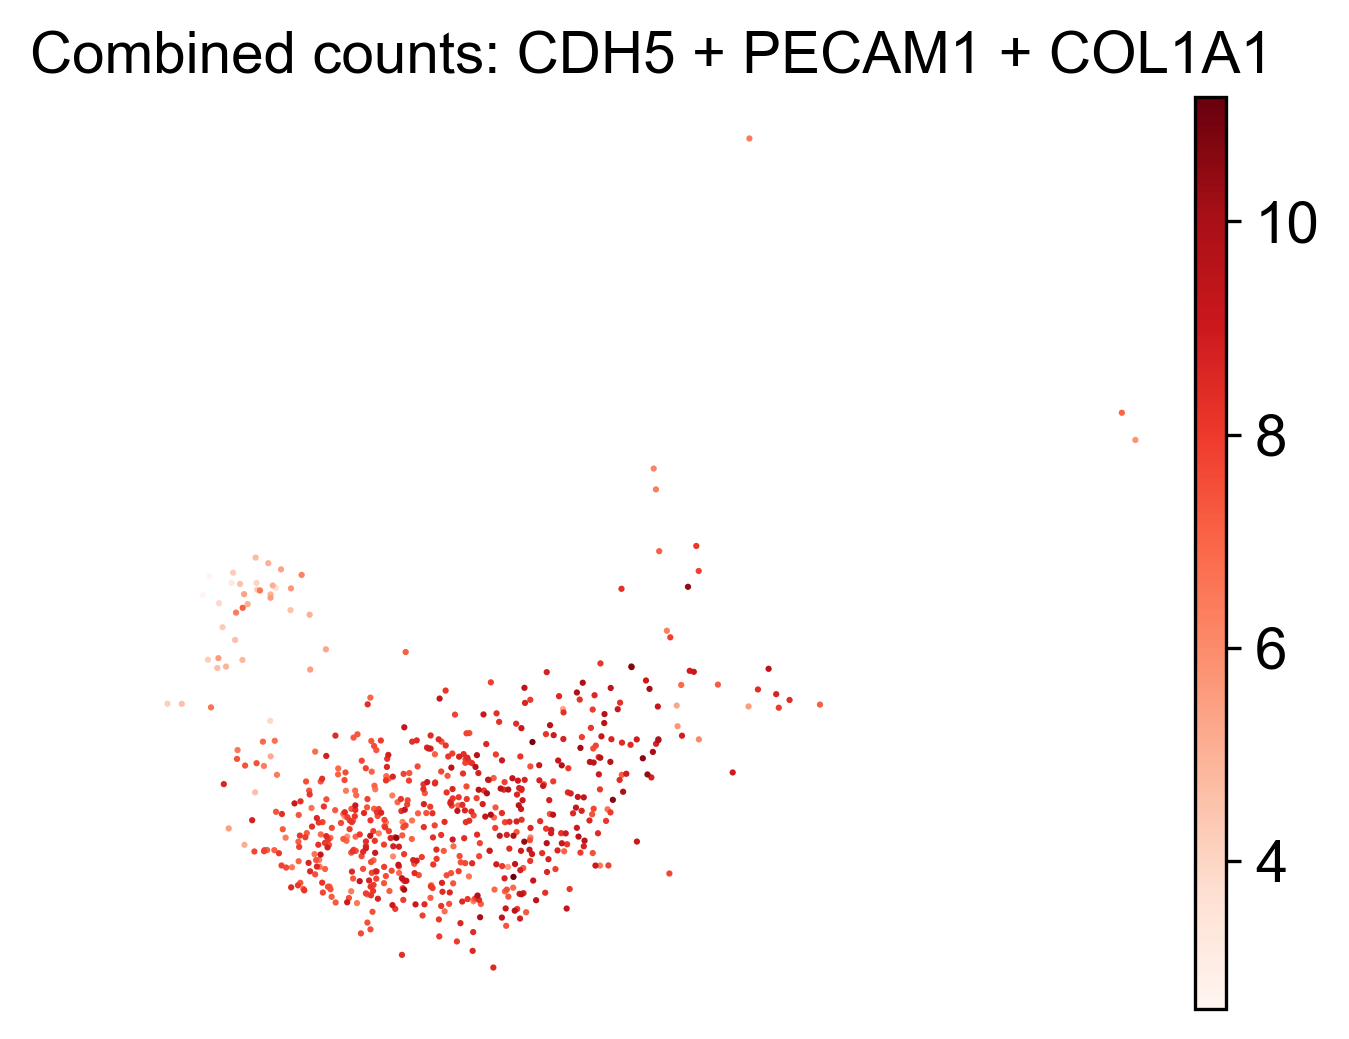

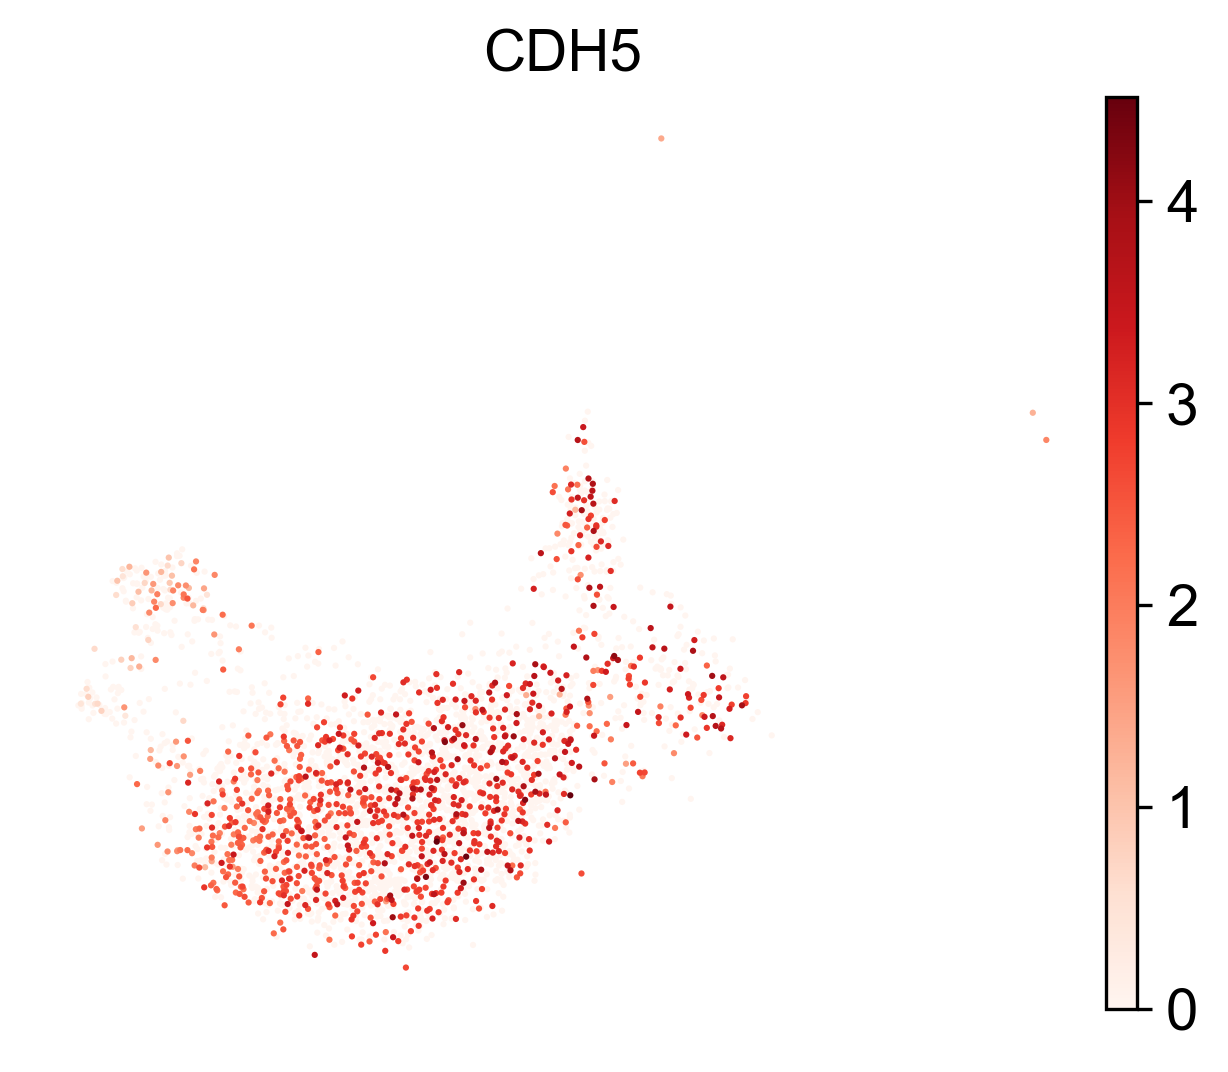

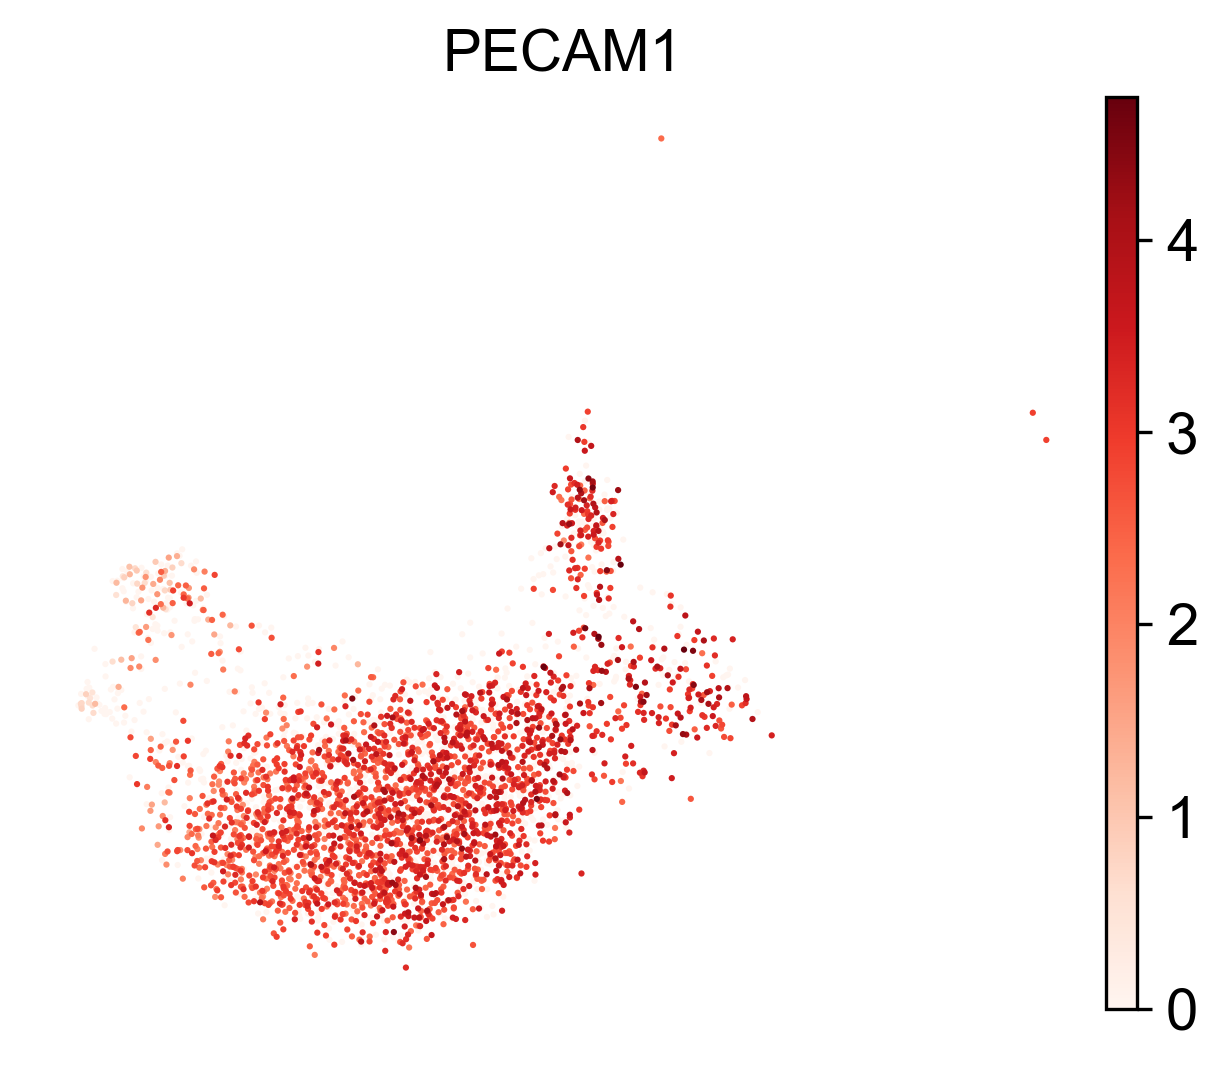

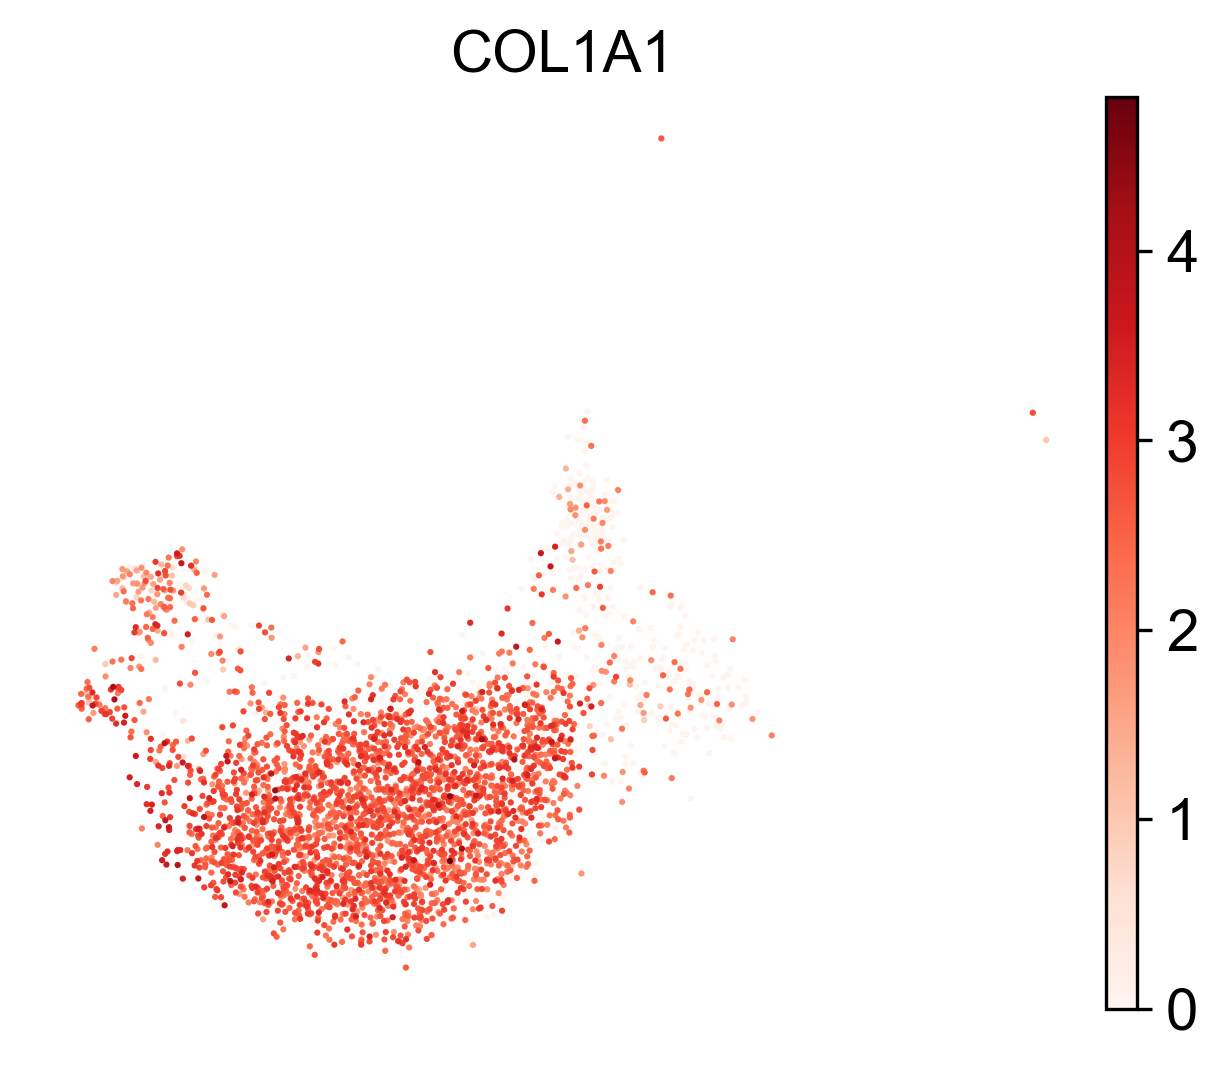

{'genes_plotted': ['CDH5', 'PECAM1', 'COL1A1'], 'genes_missing': []}

In [16]:
plot_key_genes(cluster_2, genes=["CDH5", "PECAM1", "COL1A1"], output_dir=output_dir, split_conditions=False,all_present = True)
plot_key_genes(cluster_2, genes=["CDH5", "PECAM1", "COL1A1"], output_dir=output_dir, split_conditions=False,all_present = False)


In [ ]:
sc.pl.umap(res_0_2, color=["clusters", "condition"], wspace=0.4, ncols=2, save="_overview.png", show=True)

highlight_umap(res_0_2, "condition", size=10, ncols=3, output_path=output_dir / "umap_condition_highlight.png",
    palette=condition_colormap)

sig_1_list = ["PECAM1", "CDH5"]
sig_2_list = ["COL1A1", "COL3A1"]
marker_summary = understand_marker_genes(cluster_2, sig_1_list, sig_2_list, output_dir=output_dir,
    thresh=0.0, sig1_name="Endothelial", sig2_name="Fibroblast")
print(marker_summary)

run_subcluster_pipeline(cluster_2, output_dir=output_dir, leiden_resolutions=leiden_resolutions)
plot_cluster_composition(res_0_2, cluster_colormap=cluster_colormap, output_dir=output_dir)

sc.tl.rank_genes_groups(res_0_2, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs=True)
sc.pl.rank_genes_groups_dotplot(res_0_2, n_genes=5, values_to_plot="logfoldchanges",
    cmap="bwr", vmin=-4, vmax=4, colorbar_title="log fold change", save="_markers.png",
    show=True)

gene_dz_excel = pd.read_excel(genes_dz_path)
gene_cc_excel = pd.read_excel(genes_cc_path)
all_genes = pd.concat([gene_dz_excel, gene_cc_excel], ignore_index=True)

key_genes = [g for g in all_genes.Gene if g in res_0_2.var_names]
cluster2_key_genes = [g for g in all_genes.Gene if g in cluster_2.raw.var_names]

plot_key_genes(cluster_2, cluster2_key_genes, output_dir=output_dir, split_conditions=True,
    save_name="cluster2_sub04.png", cmap="Reds")
plot_key_genes(cluster_2, cluster2_key_genes, output_dir=output_dir, split_conditions=False,
    save_name="cluster2_sub04.png", cmap="Reds")

gene_diagnostics(res_0_2, gene="CDH5", output_dir=output_dir)

# Example extra call for full dataset key genes.
# plot_key_genes(res_0_2, key_genes, output_dir=output_dir, split_conditions=True, save_name="gene_umap_by_condition.png")
